In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [3]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

### Preparing the dataset 

Use only the following columns:

* `'engine_displacement'`,
* `'horsepower'`,
* `'vehicle_weight'`,
* `'model_year'`,
* `'fuel_efficiency_mpg'`

In [4]:
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']] 
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


### EDA

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

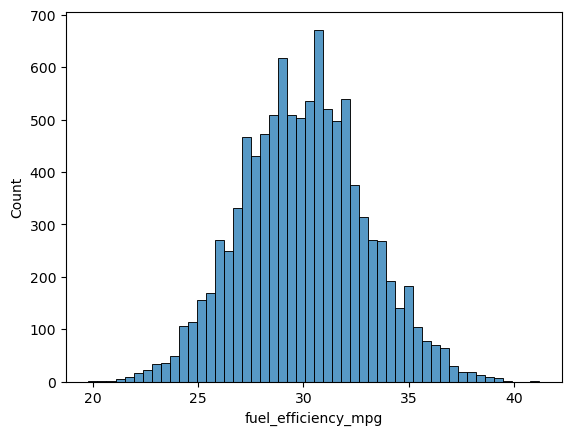

In [10]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

* The `fuel_efficiency_mpg` variable does not have a long tail. It has a normal distibution 

### Question 1

There's one column with missing values. What is it?

* `'engine_displacement'`
* `'horsepower'`
* `'vehicle_weight'`
* `'model_year'`

In [18]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


### Question 2

What's the median (50% percentile) for variable `'horsepower'`?

- 204
- 254
- 304
- 354

In [19]:
df.horsepower.median()

254.0

### Prepare and split the dataset

Shuffle the filtered dataset and create the split exactly as in the lecture:

```python

```

For Q5, repeat the same block with each listed seed. For Q6, use seed `9`

In [21]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
* Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good

### filling with mean

In [22]:
mean_hp = df_train['horsepower'].mean()
df_train_mean = df_train.copy()
df_train_mean['horsepower'] = df_train['horsepower'].fillna(mean_hp)

In [36]:
X_mean = np.array(df_train_mean[['engine_displacement','horsepower', 'vehicle_weight', 'model_year']])
X_mean

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]])

In [37]:
y_mean = np.array(df_train_mean['fuel_efficiency_mpg'])
y_mean

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ])

In [38]:
# XTX_mean = X_mean.T.dot(X_mean)
# XTX_inv_mean = np.linalg.inv(XTX_mean)
# w_full_mean = XTX_inv_mean.dot(X_mean.T).dot(y_mean)
# w_full_mean

array([-0.00122309, -0.00957784, -0.0041717 ,  0.02654101])

In [41]:
# w0_mean = w_full_mean[0]
# w_mean = w_full_mean[1:]

In [43]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [46]:
w0_mean, w_mean = train_linear_regression(X_mean, y_mean)

In [67]:
w0_mean, w_mean

(np.float64(-153.2964563917389),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [50]:
y_pred_mean = w0_mean + X_mean.dot(w_mean)
y_pred_mean

array([33.9590606 , 29.31436861, 32.76131994, ..., 29.30040609,
       31.92376266, 29.67268373])

<Axes: ylabel='Count'>

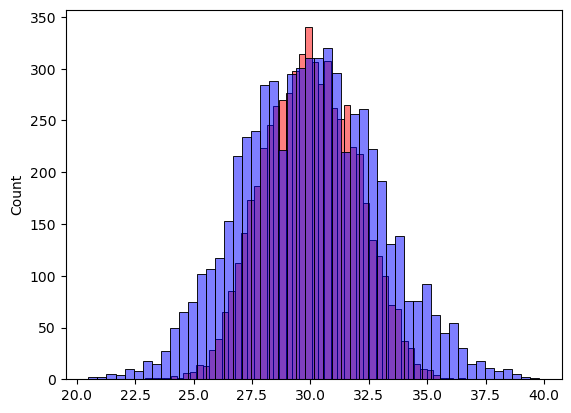

In [54]:
sns.histplot(y_pred_mean, color='red', alpha=0.5, bins=50)
sns.histplot(y_zero, color='blue', alpha=0.5, bins=50)

In [10]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [56]:
rmse(y_mean, y_pred_mean)

np.float64(2.198101430917093)

In [60]:
df_val_mean = df_val.copy()
df_val_mean['horsepower'] = df_val_mean['horsepower'].fillna(mean_hp)

In [11]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(mean_hp)
    X = df_num.values
    return X

In [66]:
X_val_mean = np.array(df_val_mean[['engine_displacement','horsepower', 'vehicle_weight', 'model_year']])
y_val_mean = np.array(df_val_mean['fuel_efficiency_mpg'])

In [74]:
y_pred = w0_mean + X_val_mean.dot(w_mean)
round(rmse(y_val_mean, y_pred),3)

np.float64(2.202)

### filling with zeros

In [23]:
df_train_zero = df_train.copy()
df_train_zero['horsepower'] = df_train['horsepower'].fillna(0)

In [35]:
X_zero = np.array(df_train_zero[['engine_displacement','horsepower', 'vehicle_weight', 'model_year']])
X_zero

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]])

In [34]:
y_zero = np.array(df_train_zero['fuel_efficiency_mpg'])
y_zero

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ])

In [40]:
# XTX_zero = X_zero.T.dot(X_zero)
# XTX_inv_zero = np.linalg.inv(XTX_zero)
# w_full_zero = XTX_inv_zero.dot(X_zero.T).dot(y_zero)
# w_full_zero

array([-0.00225267,  0.0048971 , -0.00432331,  0.02624709])

In [42]:
# w0_zero = w_full_zero[0]
# w_zero = w_full_zero[1:]

In [51]:
w0_zero, w_zero = train_linear_regression(X_zero, y_zero)

In [52]:
y_pred_zero = w0_zero+ X_zero.dot(w_mean)
y_pred_zero

array([33.37055511, 28.72586312, 32.17281445, ..., 28.7119006 ,
       31.33525717, 29.08417824])

<Axes: ylabel='Count'>

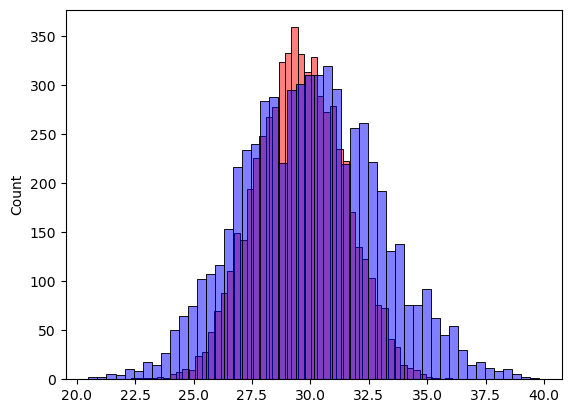

In [53]:
sns.histplot(y_pred_zero, color='red', alpha=0.5, bins=50)
sns.histplot(y_zero, color='blue', alpha=0.5, bins=50)

In [57]:
rmse(y_zero, y_pred_zero)

np.float64(2.2949900963363077)

In [70]:
df_val_zero = df_val.copy()
df_val_zero['horsepower'] = df_val_zero['horsepower'].fillna(0)

In [71]:
X_val_zero = np.array(df_val_zero[['engine_displacement','horsepower', 'vehicle_weight', 'model_year']])
y_val_zero = np.array(df_val_zero['fuel_efficiency_mpg'])

In [73]:
y_pred_zero = w0_zero + X_val_zero.dot(w_zero)
round(rmse(y_val_zero, y_pred_zero), 3)

np.float64(2.205)

### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0. 
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100

In [75]:
X_zero

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]])

In [76]:
y_zero

array([32.5, 29.1, 34.1, ..., 27.7, 31.6, 28. ])

In [8]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [78]:
w0_zero, w_zero = train_linear_regression_reg(X_zero, y_zero, r=0.01)
y_pred_zero = w0_zero + X_val_zero.dot(w_zero)
round(rmse(y_val_zero, y_pred_zero),4)

np.float64(2.2058)

In [80]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0_zero, w_zero = train_linear_regression_reg(X_zero, y_zero, r=r)
    y_pred_zero = w0_zero + X_val_zero.dot(w_zero)
    
    score = round(rmse(y_val_zero, y_pred_zero), 4)
    
    print(r, w0_zero, score)

0 -153.88496188200298 2.2053
0.01 -148.30921244130587 2.2058
0.1 -111.83871039265854 2.2241
1 -32.33186596498771 2.3492
5 -7.772852209985949 2.4094
10 -3.9871164160106405 2.4195
100 -0.4082196488472487 2.4292


### Question 5 

* We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
* Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
* For each seed, do the train/validation/test split with 60%/20%/20% distribution.
* Fill the missing values with 0 and train a model without regularization.
* For each seed, evaluate the model on the validation dataset and collect the RMSE scores. 
* What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
* Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different. 
> If standard deviation of scores is low, then our model is *stable*.

In [6]:
features = ['engine_displacement','horsepower', 'vehicle_weight', 'model_year']

In [90]:
scores = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)

    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values

    X_train = df_train[features].fillna(0).values
    X_val = df_val[features].fillna(0).values


    w0, w = train_linear_regression_reg(X_train, y_train, r=0)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    scores.append(score)
    print(seed, round(score, 4))

std = np.std(scores)
round(std, 3)

0 2.2392
1 2.2021
2 2.1634
3 2.2044
4 2.2019
5 2.2458
6 2.2697
7 2.1908
8 2.2166
9 2.207


np.float64(0.029)

### Question 6

* Split the dataset like previously, use seed 9.
* Combine train and validation datasets.
* Fill the missing values with 0 and train a model with `r=0.001`. 
* What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236
- 22.10
- 221.0

In [12]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

idx = np.arange(n)
np.random.seed(9)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

y_full_train = df_full_train['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

X_full_train = df_full_train[features].fillna(0).values
X_test = df_test[features].fillna(0).values

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
y_pred = w0 + X_test.dot(w)

score = rmse(y_test, y_pred)
print(round(score, 3))

2.236
